In [11]:
import sys
import os
from typing import NamedTuple
import math
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt
import pickle


sys.path.append(os.path.join(os.getcwd(), '../'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from models import bom_rs as bom
from models import hgm_rs as hgm

In [12]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm_rs' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/models/hgm_rs.py'>

In [13]:
def assemble(boms_scores_per_neuron, hgms_scores_per_neuron):
	neurons_labels = [scores_per_neuron[0].columns for scores_per_neuron in hgms_scores_per_neuron]

	boms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in hgms_scores_per_neuron]

	neuron_scores = dict()
	boms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in hgms_scores_per_neuron]
	for label_list, score_bom_list, score_hgm_list in zip(neurons_labels, boms_scores_per_neuron_avg, hgms_scores_per_neuron_avg):
		sort_indices = np.argsort(score_hgm_list)[::-1]
		label_list = label_list[sort_indices]
		score_bom_list = score_bom_list[sort_indices]
		score_hgm_list = score_hgm_list[sort_indices]

		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_bom_new, score_hgm_new = np.array(score_bom_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_bom_new = score_bom_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_bom_new, score_hgm_new)
				else:
					score_bom_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_bom_prev, score_bom_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

In [14]:
# file_ids = list(range(0, 12+1))
# file_ids = [0,	# paper
# 			1,	# nice states
# 			2,	# nice manifold
# 			5,	# variety
# 			6,	# nice quiescence
# 			7,	# nice states
# 			9,	# nice heatmap
# 			11]	# variety
file_ids = [0]

In [15]:
path = os.path.join(read_utils.get_data_path(), 'brain')

filenames = list()
boms_spn = list()
hgms_spn = list()

for file_id in file_ids:
	filename = read_utils.get_filename(read_utils.get_filepath(path, file_id))
	filenames.append(filename)

	load_path = f'../../out/predictions/{filename}/bom_rs/validation'
	bom_spn, _, _, _, _, _, _ = train_utils.load_predictions(load_path)
	boms_spn.append(bom_spn)

	load_path = f'../../out/predictions/{filename}/hgm_rs/validation'
	hgm_spn, _, _, _, _, _, _ = train_utils.load_predictions(load_path)
	hgms_spn.append(hgm_spn)

In [16]:
neuron_scores = assemble(boms_spn, hgms_spn)

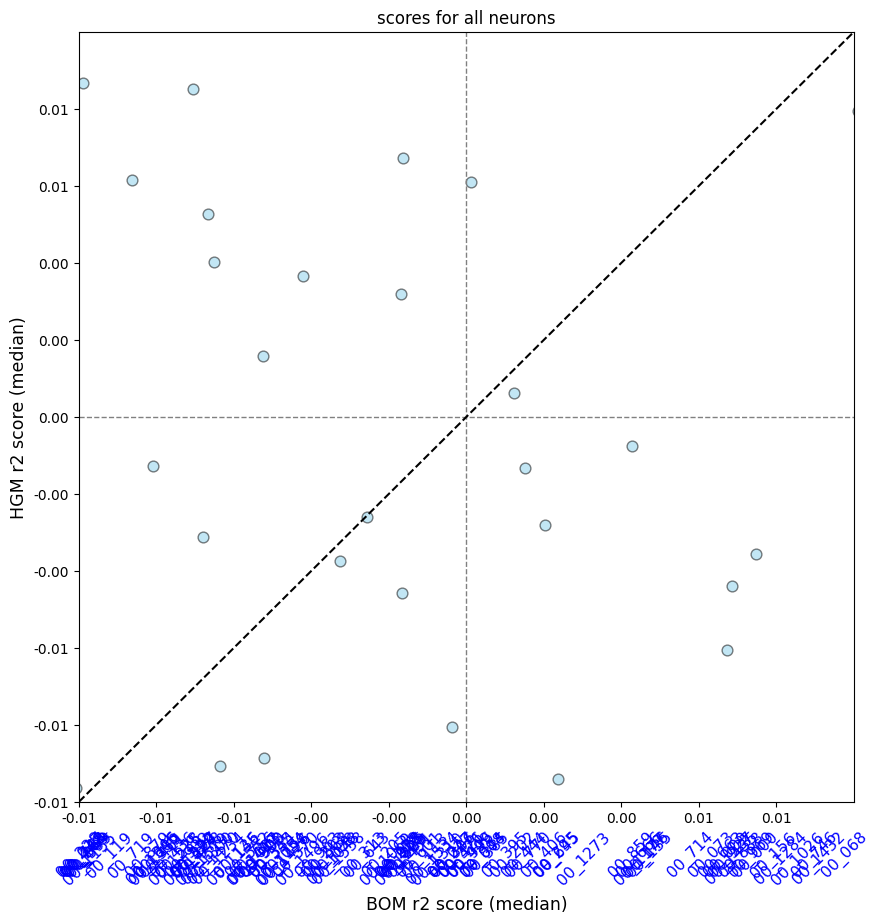

In [17]:
plot_utils.plot_performance_plot(
	neuron_scores, None,
	title='scores for all neurons', limits=(-0.01, 0.01, -0.01, 0.01), force_medians=False
)

In [18]:
# plot_utils.plot_improvement_plot(
# 	neuron_scores, None,
# 	title='improvements for all neurons', limits=(-0.01, 0.01, -0.01, 0.01), force_medians=False
# )

In [19]:
relevant_hgm_n = {key: value for key, value in neuron_scores.items() if 0 < np.median(value[0]) < np.median(value[1])}

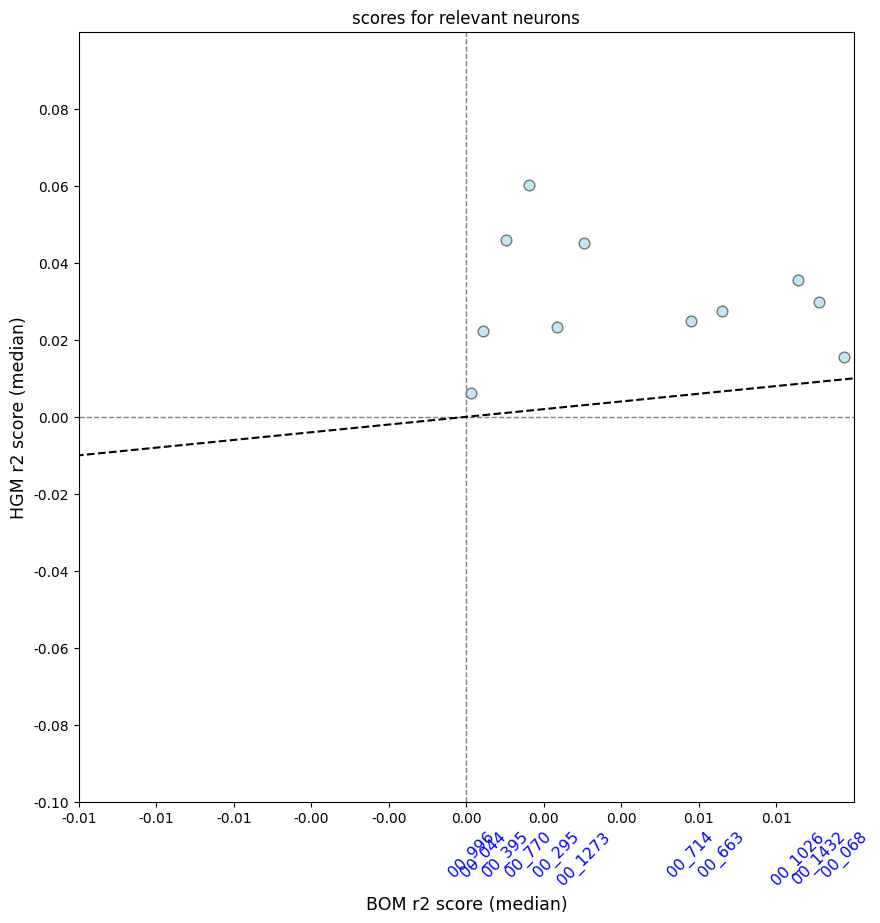

In [20]:
plot_utils.plot_performance_plot(
	{key: neuron_scores[key] for key in relevant_hgm_n}, None,
	title='scores for relevant neurons', limits=(-0.01, 0.01, -0.1, 0.1), force_medians=False
)

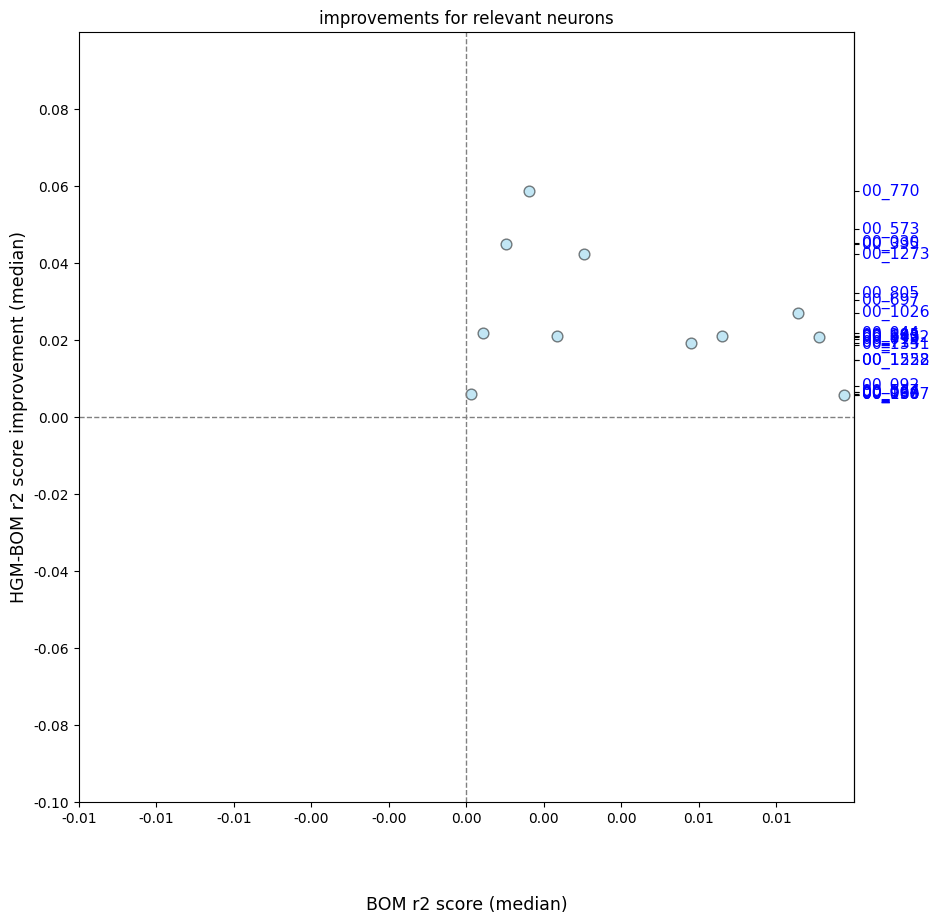

In [21]:
plot_utils.plot_improvement_plot(
	{key: neuron_scores[key] for key in relevant_hgm_n}, None,
	title='improvements for relevant neurons', limits=(-0.01, 0.01, -0.1, 0.1), force_medians=False
)

# single traces

In [22]:
file_id = 0

In [23]:
# read
path = os.path.join(read_utils.get_data_path(), 'brain')

(filename,
 traces,
 states, markers) = read_utils.get_data(path, file_id)

# # clear nan values
# for i in range(len(file_ids)):
# 	mask = markers[i].notna().all(axis=1)
#
# 	traces[i] = traces[i][mask]
# 	markers[i] = markers[i][mask]
# 	states[i] = states[i][mask]
#
# 	#filenames[i] = filenames[i][mask]

# # remove unused discrete state labels
# states = [ds[selection_bhl] for ds in states]

# naive ID unknown neurons
traces.columns = pd.Index([
	f'{file_id:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces.columns, traces.columns == ''))
])

# prep
def highpass_butter(x, fs, cutoff_hz, order=4, axis=0):
	return sp.signal.sosfiltfilt(sp.signal.butter(order, cutoff_hz, btype='highpass', fs=fs, output='sos'), x, axis=axis)
sampling_rate = read_utils.get_sampling_rate(os.path.join(path, filename))
traces = pd.DataFrame(highpass_butter(traces.values, sampling_rate, 1 / 100), columns=traces.columns)
# markers_grad = pd.DataFrame(np.gradient(markers.values, axis=0), columns=markers.columns)

In [24]:
load_path = f'../../out/predictions/{filename}/bom_rs/full'
_, bom_man, bom_rec, bom_res, bom_pres, bom_resss, bom_bss = train_utils.load_predictions(load_path)

load_path = f'../../out/predictions/{filename}/hgm_rs/full'
_, hgm_man, hgm_rec, hgm_res, hgm_pres, hgm_resss, hgm_bss = train_utils.load_predictions(load_path)

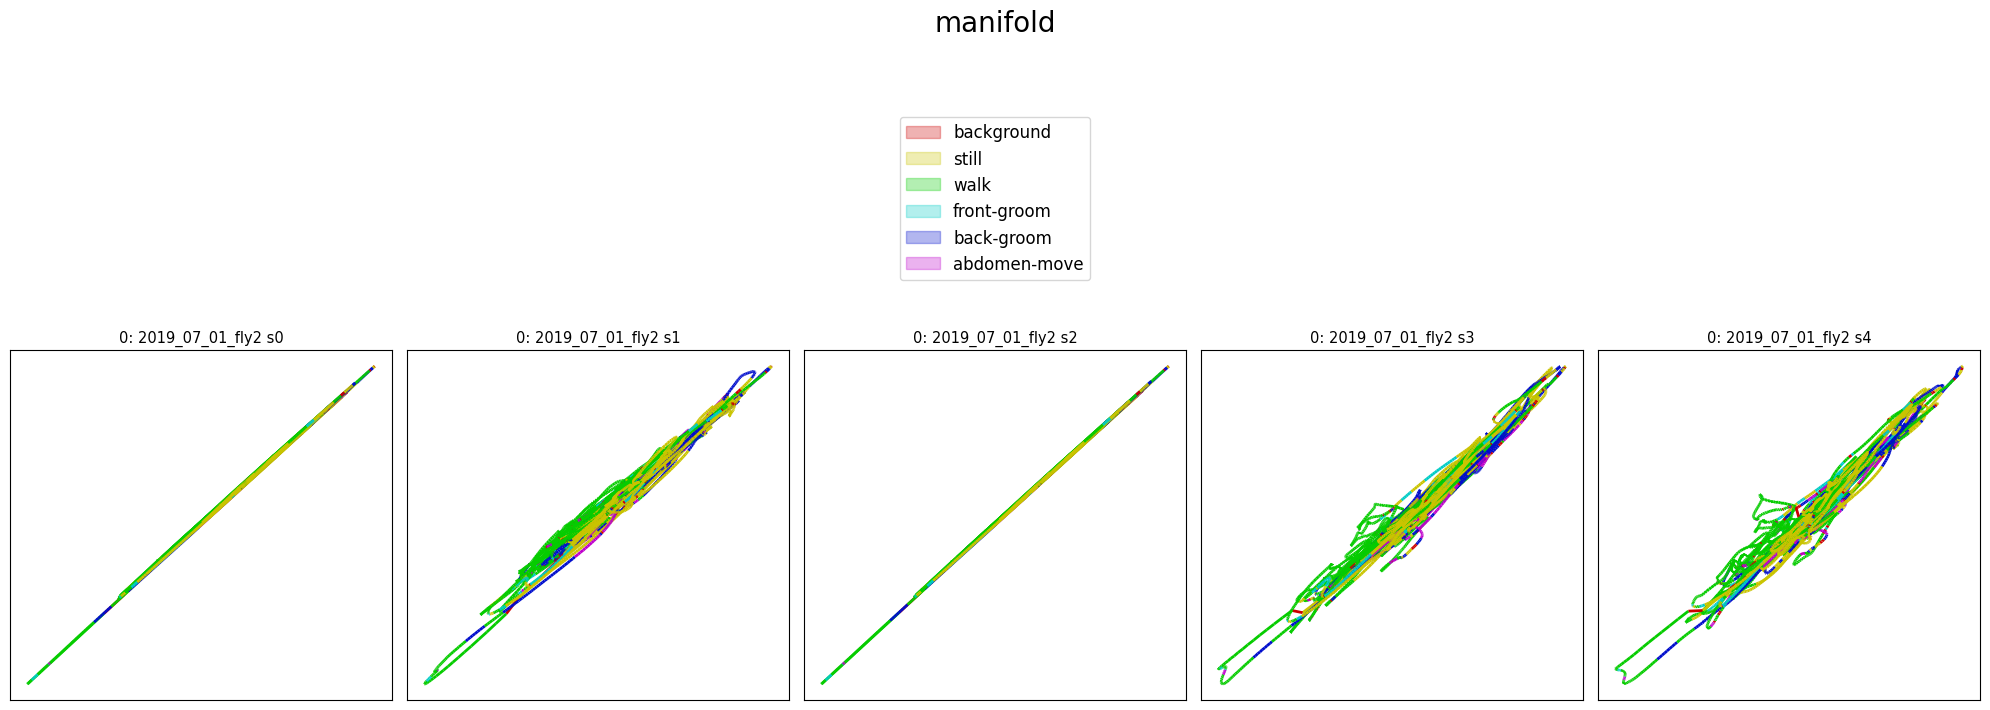

In [25]:
splits = 5
plot_utils.plot_manifolds([f'{str(file_id)}: {filename} s{s}' for s in range(splits)],
						  [hgm_man[s] for s in range(splits)],
						  [states for s in range(splits)],
						  None, None,
						  title='manifold', plots_per_row=splits, top_space=3.5,
						  save_path=None)

In [26]:
relevant_hgm_n_impr = list(reversed(sorted(relevant_hgm_n.items(), key=lambda x: np.median(x[1][1] - x[1][0]))))

print('\n'.join([f'NEURON: {key},\t\tIMPR: {np.median(val[1] - val[0]):.4f}' for key, val in relevant_hgm_n_impr[:5]]))

NEURON: 00_770,		IMPR: 0.0586
NEURON: 00_573,		IMPR: 0.0487
NEURON: 00_030,		IMPR: 0.0452
NEURON: 00_395,		IMPR: 0.0448
NEURON: 00_1273,		IMPR: 0.0422


In [27]:
neurons = ['00_1015', '00_440']

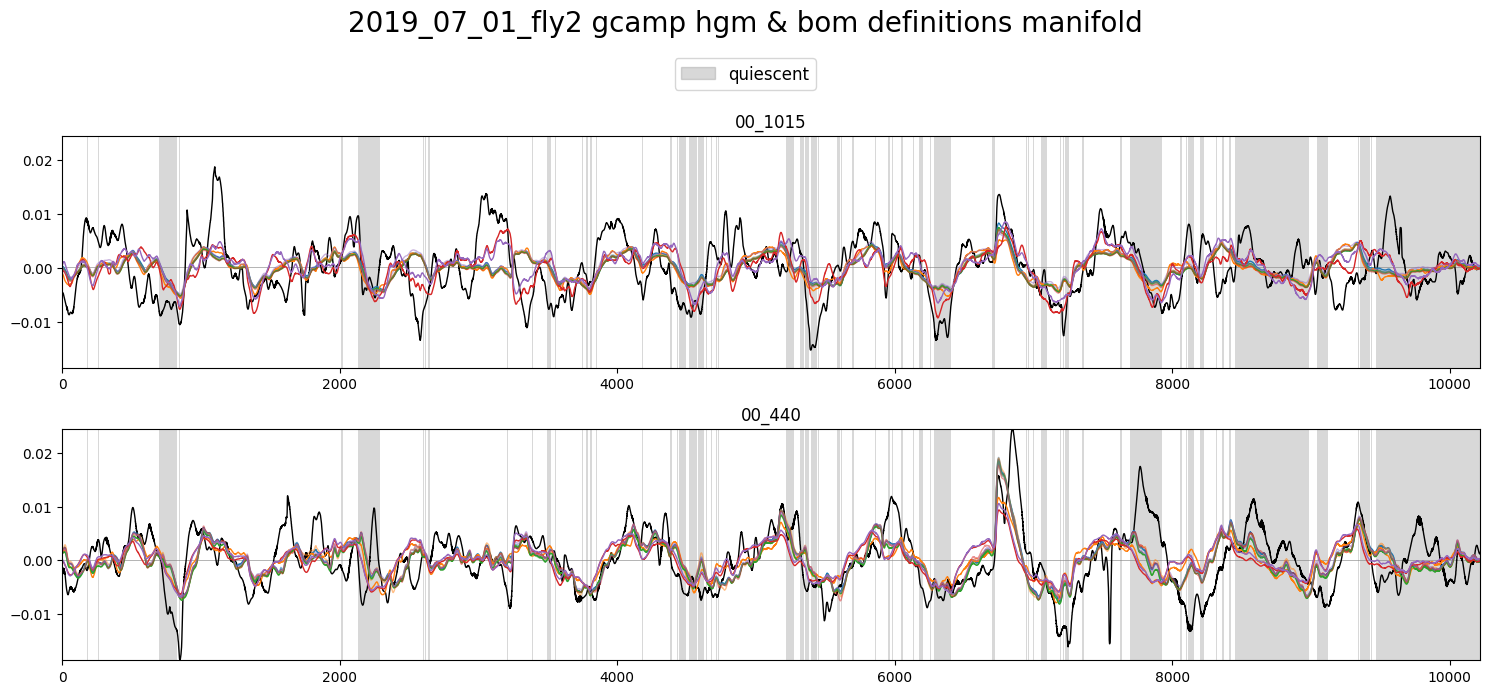

In [28]:
splits = 5
plot_utils.plot_traces_splits(
	[hgm_rec[i][neurons] for i in range(splits)],
	[bom_rec[i][neurons] for i in range(splits)],
	traces[neurons],
	states[['still']], label='quiescent',
	title=f'{filename} gcamp hgm & bom definitions manifold', ylimits=None, plots_per_row=1,
	save_path=None)  #'../../out/plots/GCAMP_MAN'

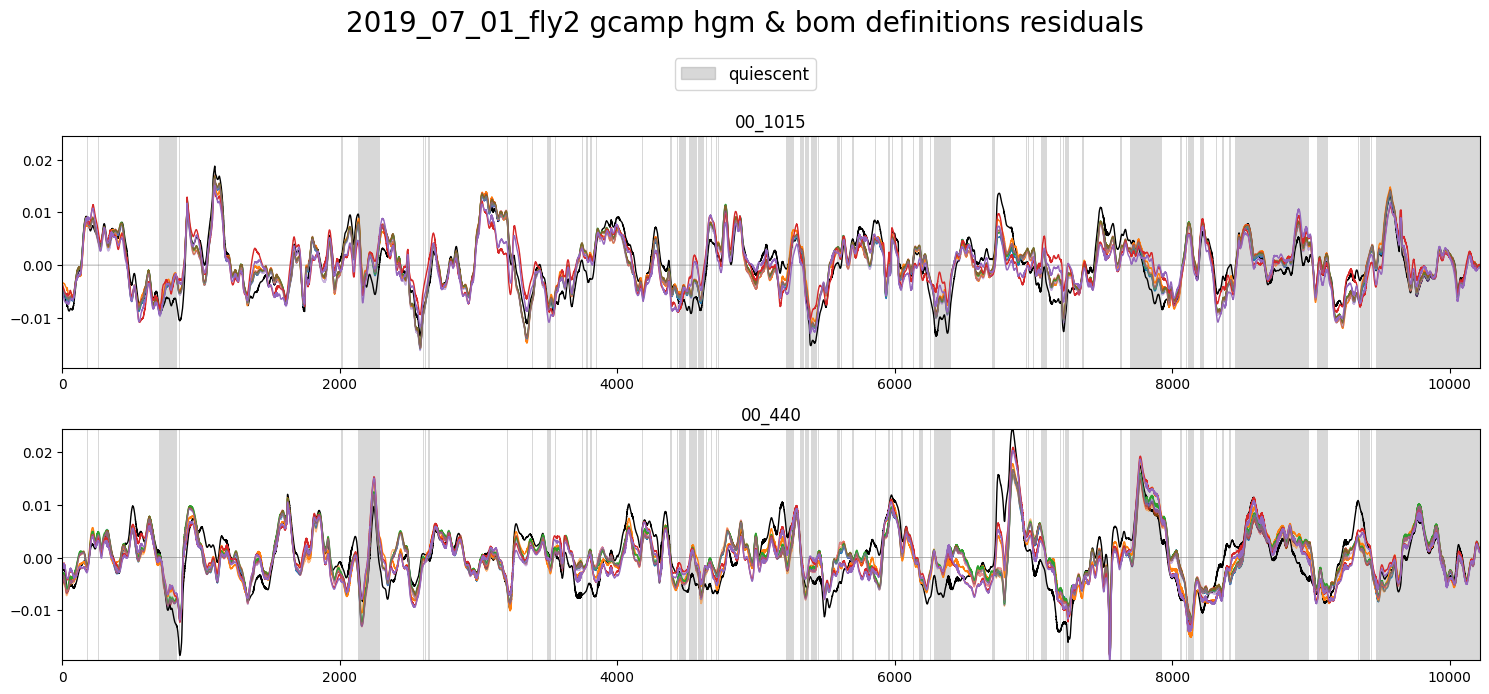

In [29]:
splits = 5
plot_utils.plot_traces_splits(
	[hgm_res[i][neurons] for i in range(splits)],
	[bom_res[i][neurons] for i in range(splits)],
	traces[neurons],
	states[['still']], label='quiescent',
	title=f'{filename} gcamp hgm & bom definitions residuals', ylimits=None, plots_per_row=1,
	save_path=None)  #'../../out/plots/GCAMP_MAN'

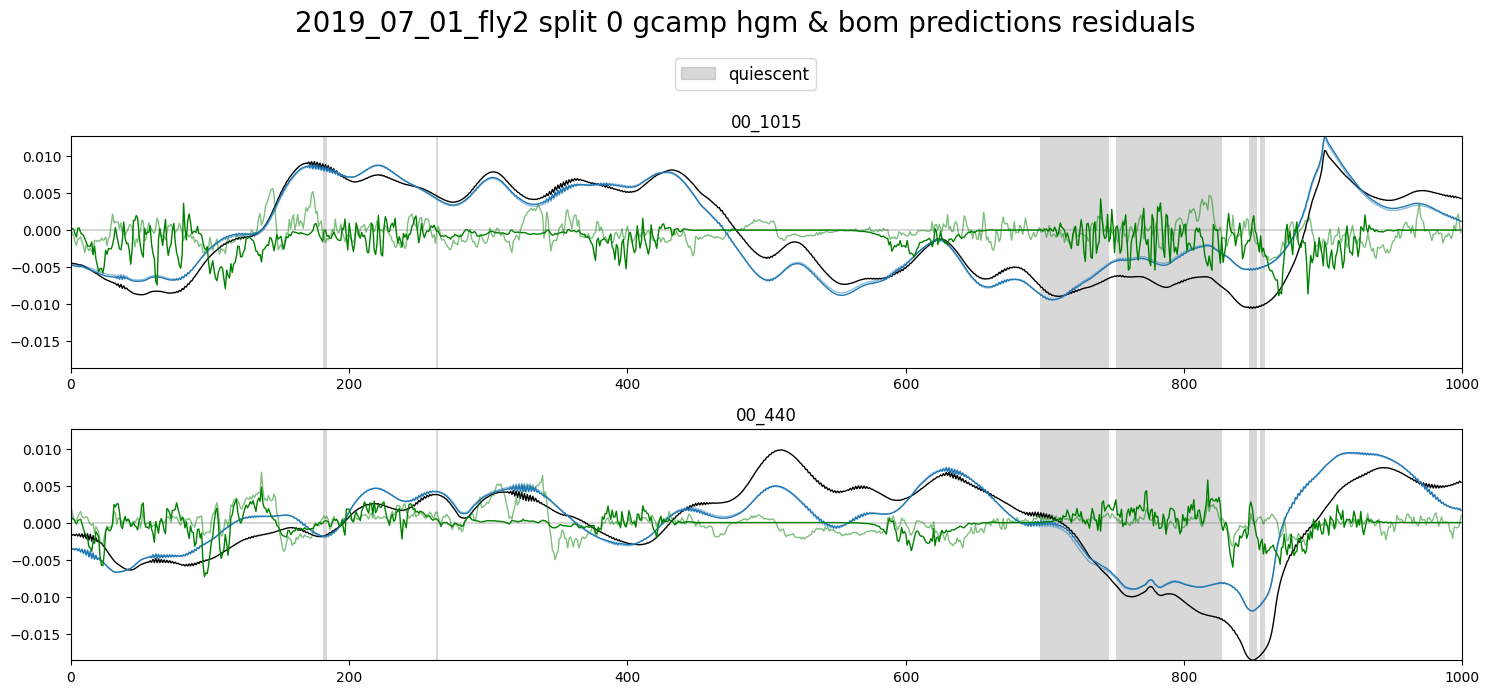

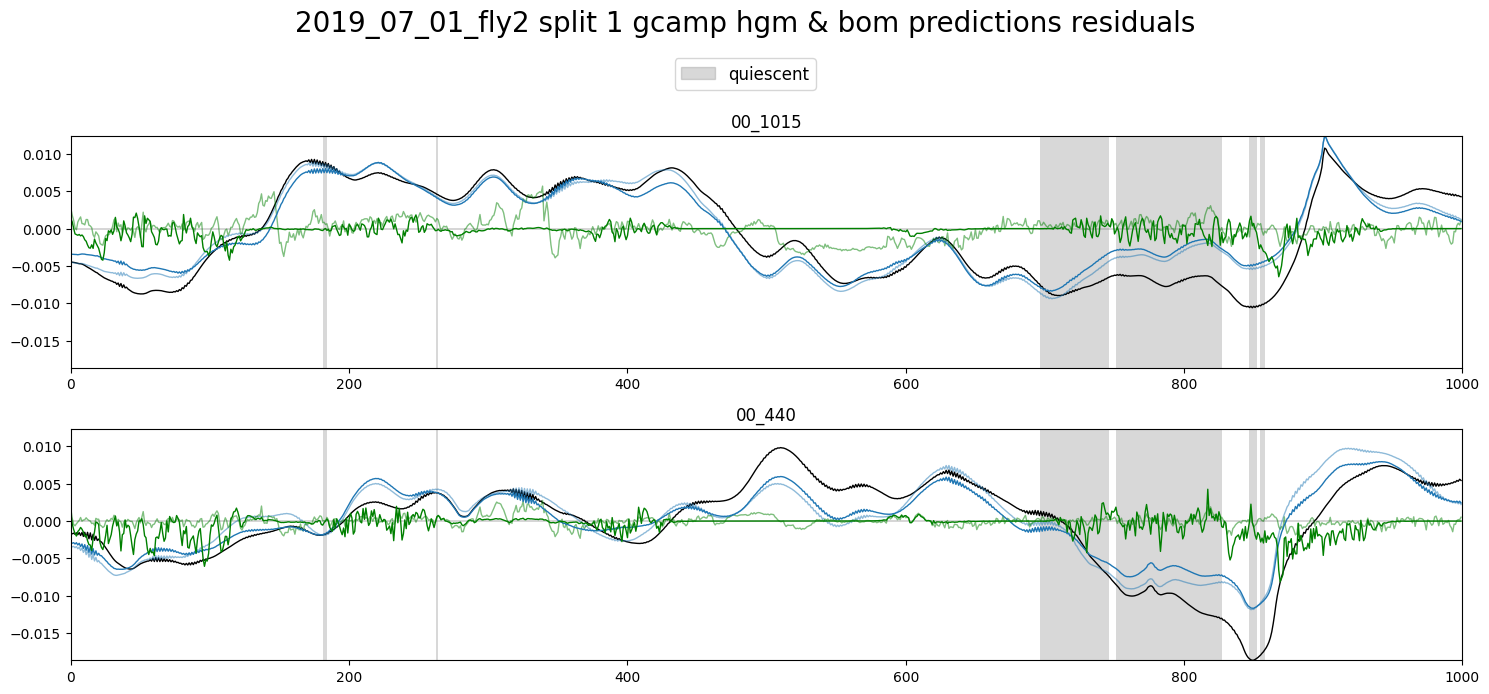

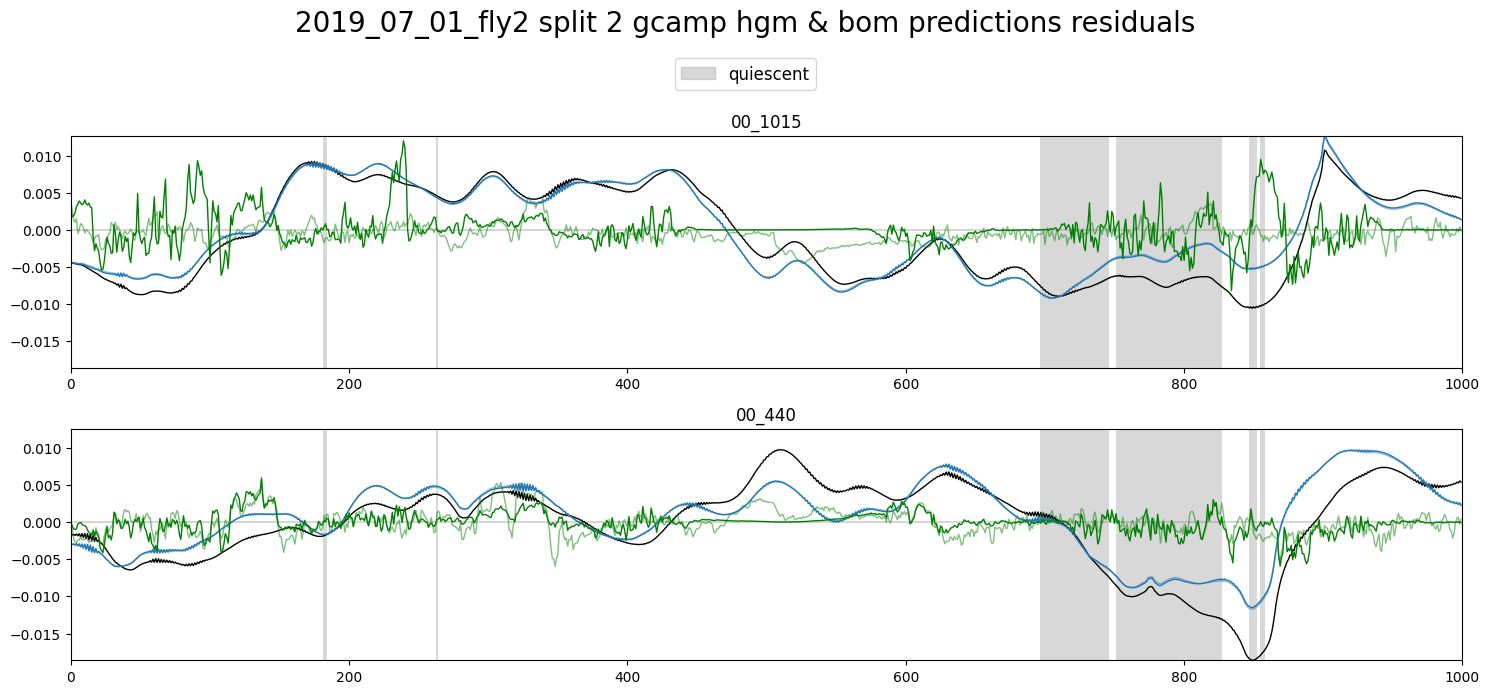

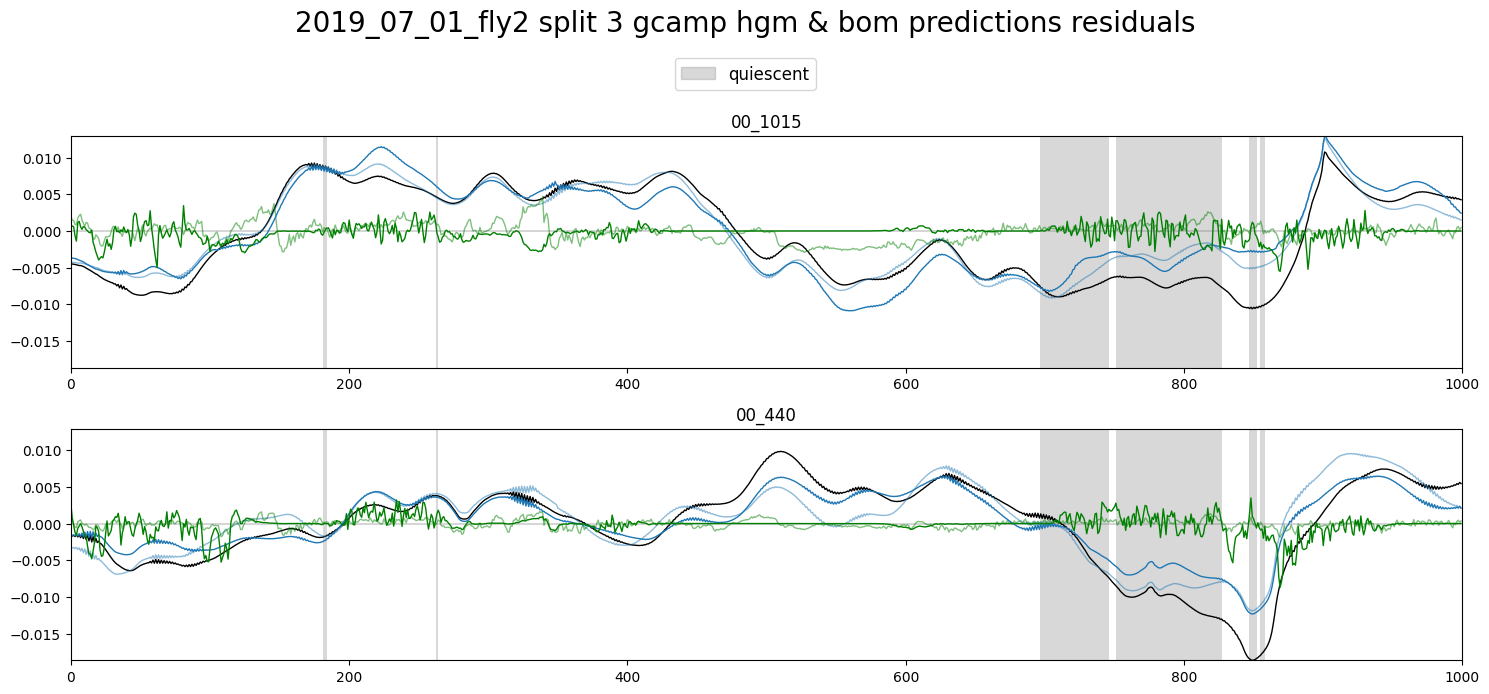

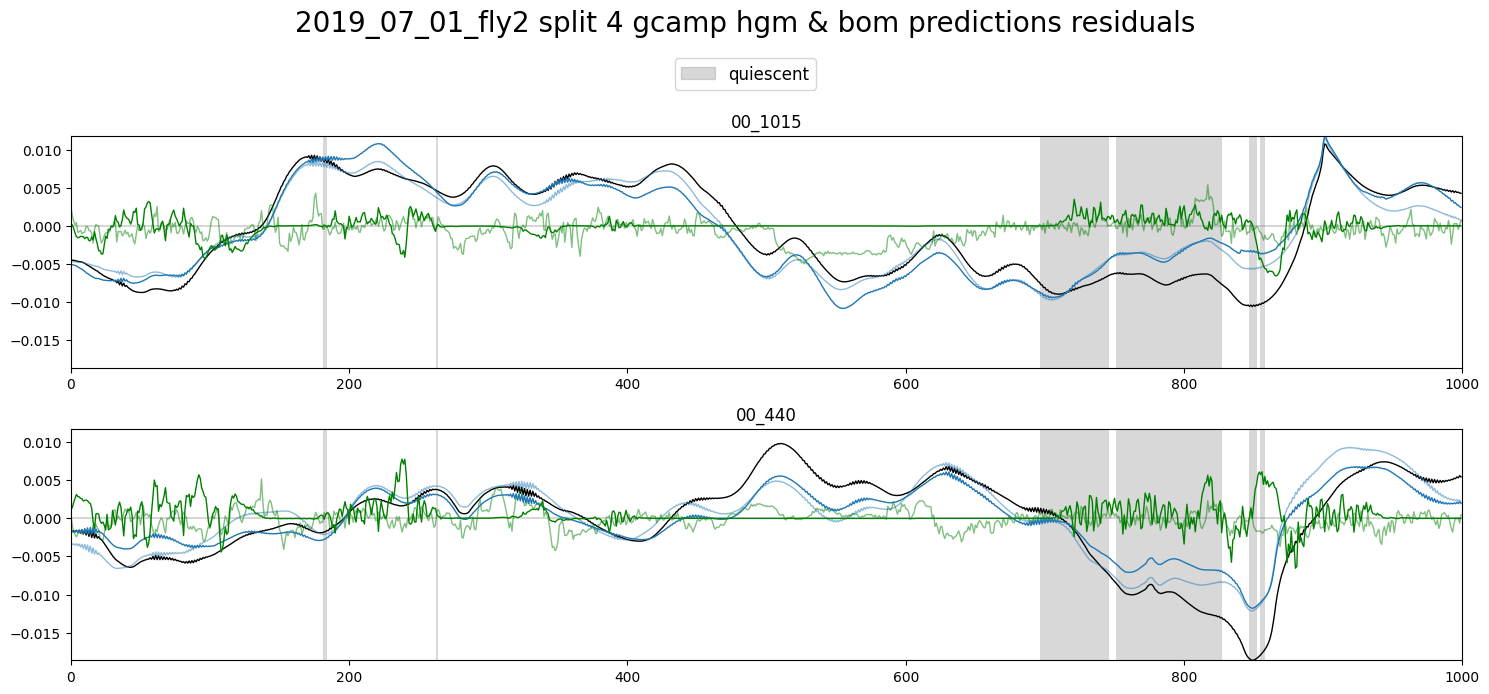

In [30]:
max_x = 1000

splits = 5
for i in range(splits):
	plot_utils.plot_traces_splits_pairs(
		[hgm_res[i][neurons].iloc[:max_x, :],
		 hgm_pres[i][neurons].iloc[:max_x, :]],
		[bom_res[i][neurons].iloc[:max_x, :],
		 bom_pres[i][neurons].iloc[:max_x, :]],
		traces[neurons].iloc[:max_x, :],
		states[['still']].iloc[:max_x, :], label='quiescent',
		title=f'{filename} split {i} gcamp hgm & bom predictions residuals', ylimits=None, plots_per_row=1,
		save_path=None)  #../../out/plots/f'GCAMP_PRES_S{i}'

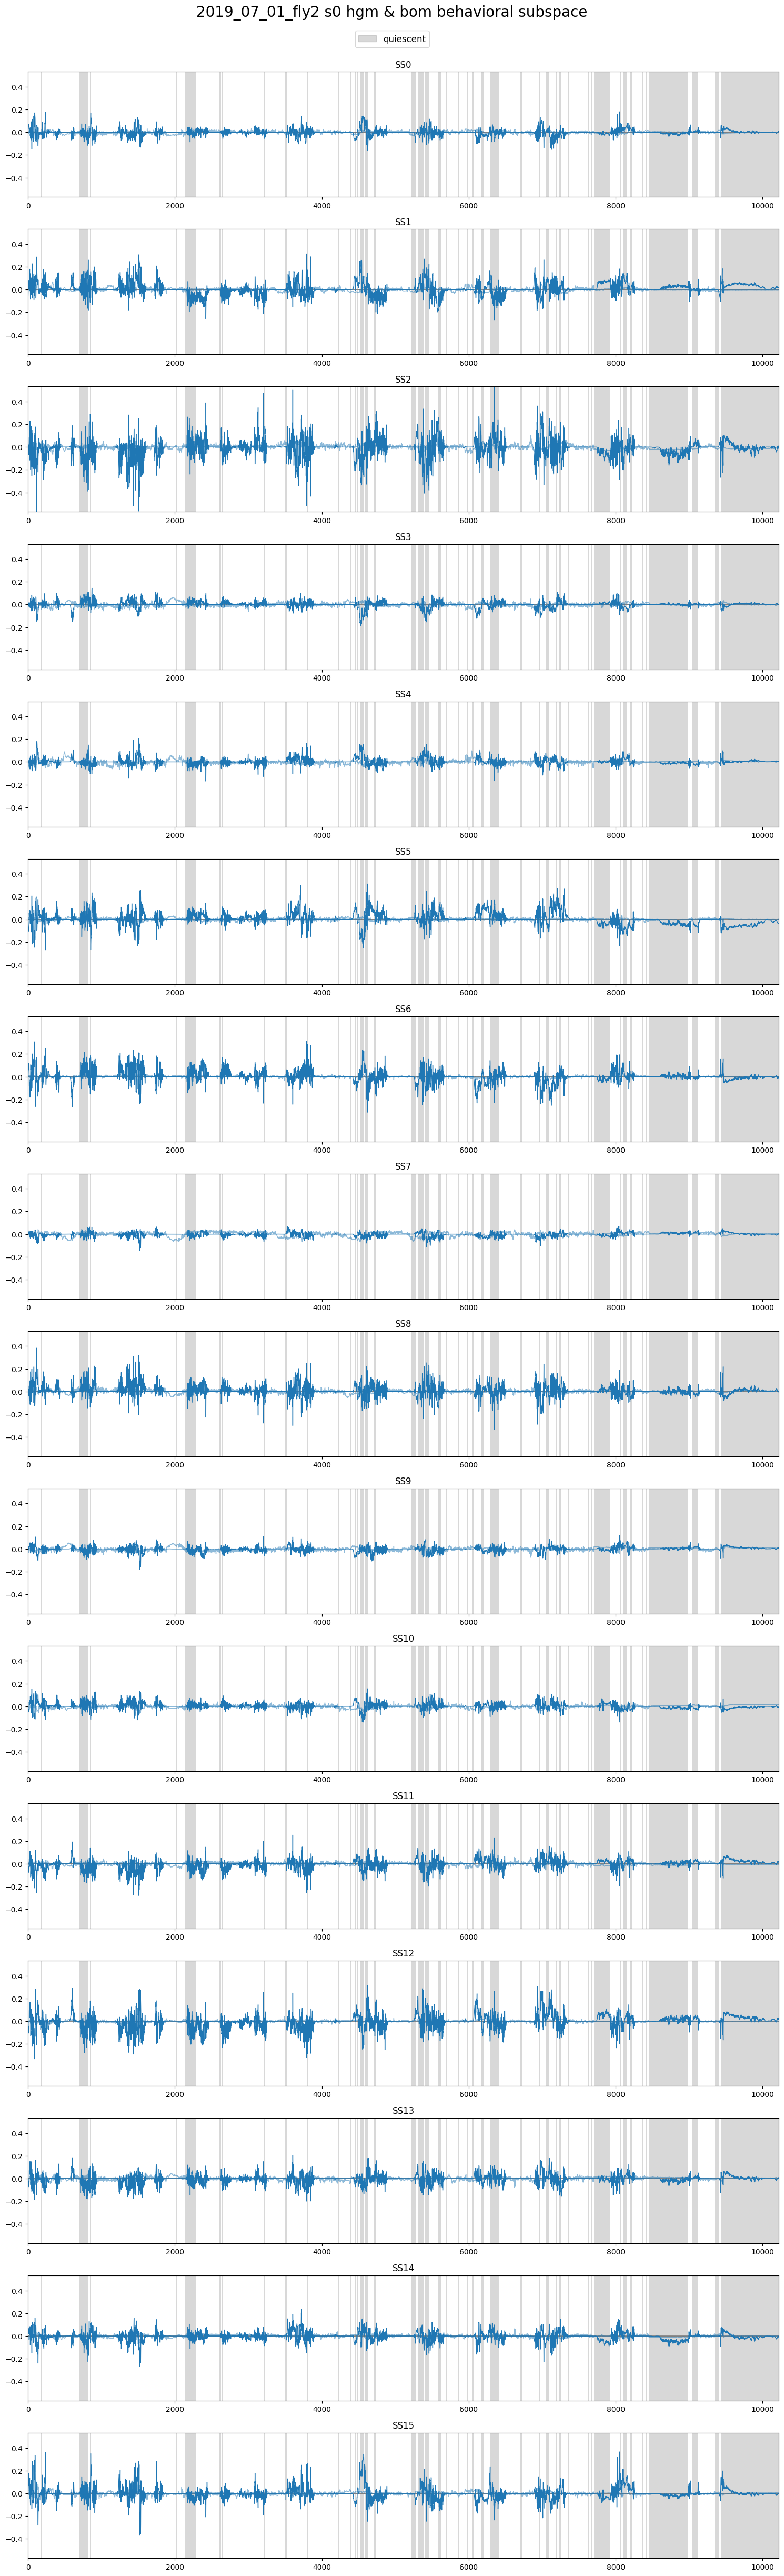

In [31]:
splits = 5
plot_utils.plot_traces_splits(
	[hgm_bss[i] for i in range(splits)][0:1],
	[bom_bss[i] for i in range(splits)][0:1],
	None,
	states[['still']], label='quiescent',
	title=f'{filename} s0 hgm & bom behavioral subspace', ylimits=None, plots_per_row=1,
	save_path=None)  #'../../out/plots/GCAMP_BSS'

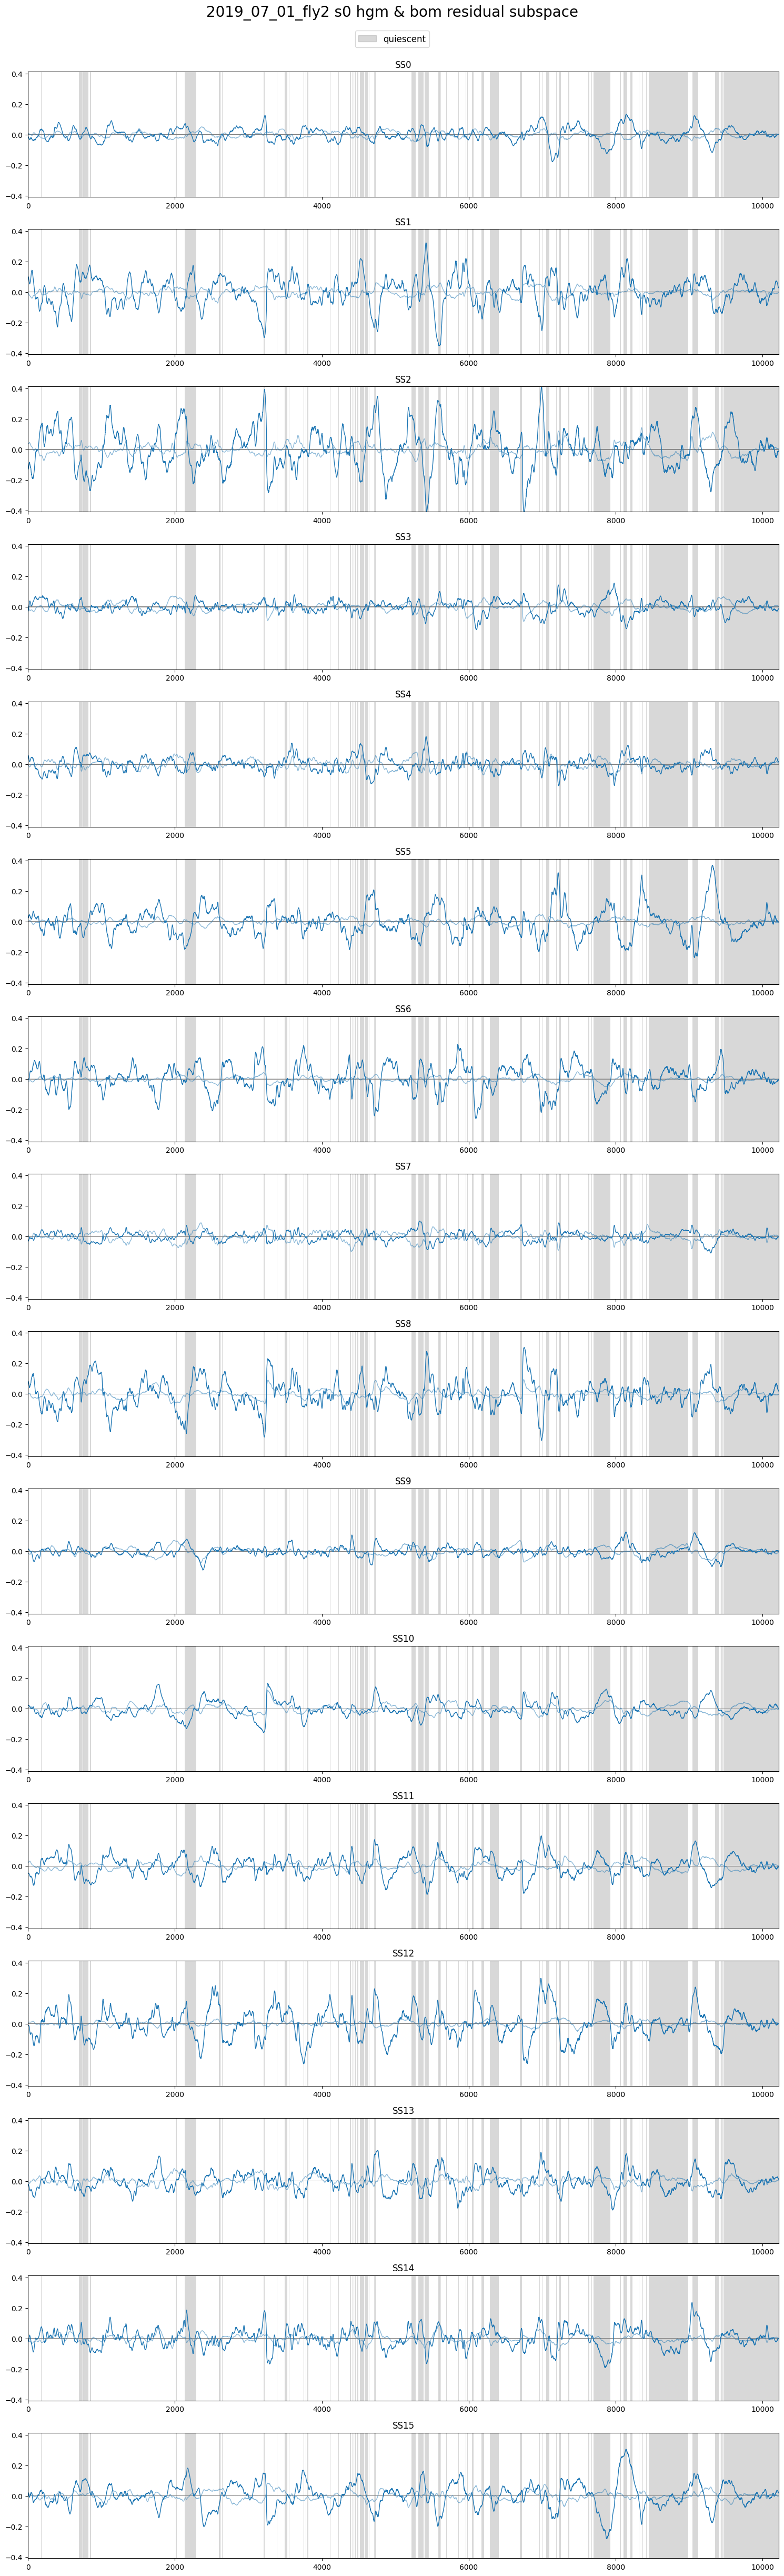

In [32]:
splits = 5
plot_utils.plot_traces_splits(
	[hgm_resss[i] for i in range(splits)][0:1],
	[bom_resss[i] for i in range(splits)][0:1],
	None,
	states[['still']], label='quiescent',
	title=f'{filename} s0 hgm & bom residual subspace', ylimits=None, plots_per_row=1,
	save_path=None)  #'../../out/plots/GCAMP_RESSS'

# model

In [40]:
manual_hyperparameters = {
	'dimensions': 2,
	'loss_man_lambda': 0.0,
	'loss_res_lambda': 1.0 - 0.0,
	'vb_reg_lambda': 0.0,
	'wb_reg_lambda': 0.0,
	'wm_reg_lambda': 0.0,
}

ll = f'll{int(manual_hyperparameters['loss_man_lambda'] * 100):02d}'

with open('../sweep/hyperparams.pkl', 'rb') as f:
    swept_hyperparameters = pickle.load(f)

bom_reg_lambdas = {
	'vb_reg_lambda': manual_hyperparameters['vb_reg_lambda'],
	# 'vb_reg_lambda': swept_hyperparameters[ll]['bom_rs']['means']['vb_reg_lambda']['geometric'],
	'wb_reg_lambda': manual_hyperparameters['wb_reg_lambda'],
	# 'wb_reg_lambda': swept_hyperparameters[ll]['bom_rs']['means']['wb_reg_lambda']['geometric'],
}
hgm_reg_lambdas = {
	'vb_reg_lambda': manual_hyperparameters['vb_reg_lambda'],
	# 'vb_reg_lambda': swept_hyperparameters[ll]['hgm_rs']['means']['vb_reg_lambda']['geometric'],
	'wb_reg_lambda': manual_hyperparameters['wb_reg_lambda'],
	# 'wb_reg_lambda': swept_hyperparameters[ll]['hgm_rs']['means']['wb_reg_lambda']['geometric'],
	'wm_reg_lambda': manual_hyperparameters['wm_reg_lambda'],
	# 'wm_reg_lambda': swept_hyperparameters[ll]['hgm_rs']['means']['wm_reg_lambda']['geometric'],
}

organism = 'fly-2023-schaffer'

In [41]:
bom_load_name = os.path.join(organism, ll, f'ss_bom_vb-{bom_reg_lambdas['vb_reg_lambda']:.2E}_wb-{bom_reg_lambdas['wb_reg_lambda']:.2E}')
hgm_load_name = os.path.join(organism, ll, f'ss_hgm_vb-{hgm_reg_lambdas['vb_reg_lambda']:.2E}_wb-{hgm_reg_lambdas['wb_reg_lambda']:.2E}_wm-{hgm_reg_lambdas['wm_reg_lambda']:.2E}')

bom_params = train_utils.load_params(bom_load_name, [filename])[0]
hgm_params = train_utils.load_params(hgm_load_name, [filename])[0]

In [42]:
N_res = bom_res[0].values
N_res_pred = bom_pres[0].values

In [43]:
# def r2_score(y_eval, y_pred, baseline):
# 	ss_res = np.sum((y_eval - y_pred) ** 2)  # ^p?
# 	ss_tot = np.sum((y_eval - baseline) ** 2)  # ^p?
# 	return np.where(ss_tot > 0.0, 1.0 - ss_res / ss_tot, 0.0)

N_zeros = np.zeros((N_res.shape[1],))

ss_res = np.sum((N_res - N_res_pred) ** 2, axis=0)  # ^p?
ss_tot = np.sum((N_res - N_zeros) ** 2, axis=0)  # ^p?

print(1.0 - ss_res / ss_tot)

print(N_res_pred - N_zeros)

[0.03337446 0.01766667 0.03602926 ... 0.02298639 0.00868059 0.03021152]
[[ 4.73231728e-04  1.65353606e-03 -1.24496214e-03 ...  1.92410660e-03
   4.08226402e-04 -4.95716505e-04]
 [ 2.50799160e-04  2.92811057e-04 -9.20583653e-04 ... -7.14335964e-05
   7.72623575e-04  7.76502172e-04]
 [ 3.37294038e-04 -5.57313904e-04  1.70850368e-05 ... -1.46172402e-03
   8.08379540e-04  1.94230704e-03]
 ...
 [ 8.55420068e-04  6.95451505e-04  1.25414203e-03 ...  4.30338784e-04
   1.25983371e-04 -1.20657563e-03]
 [ 8.45812004e-04  6.71621706e-04  1.24702534e-03 ...  4.58648985e-04
   1.50782129e-04 -1.21835197e-03]
 [ 8.46281212e-04  6.68582770e-04  1.12974252e-03 ...  3.07697764e-04
   1.12278983e-04 -1.18460050e-03]]


In [44]:
for res in bom_res:
	print(res.values.min(axis=1), res.values.max(axis=1))

[-0.01166408 -0.01165837 -0.01162528 ... -0.00625479 -0.00614902
 -0.00612967] [0.01651104 0.0166713  0.01703196 ... 0.00897271 0.00884359 0.0088906 ]
[-0.01202525 -0.01202014 -0.01198582 ... -0.00658059 -0.00647268
 -0.00645559] [0.01618101 0.01633724 0.01669811 ... 0.00909198 0.00920837 0.00923698]
[-0.01180092 -0.01179613 -0.0117638  ... -0.00626442 -0.00615626
 -0.00613864] [0.01712416 0.01728438 0.01764542 ... 0.00891176 0.00887749 0.00890622]
[-0.01207847 -0.0120749  -0.01204415 ... -0.00624217 -0.00613396
 -0.00611655] [0.01669076 0.01684685 0.01720553 ... 0.00889534 0.00908927 0.00912117]
[-0.01204476 -0.01204002 -0.01200812 ... -0.00658625 -0.00647873
 -0.00646064] [0.01618616 0.01634449 0.01670485 ... 0.00922813 0.00919881 0.00922835]


In [45]:
print(bom_params[0]['model']['VB'].max())
print(bom_params[0]['model']['WB'].max())

0.6219288965401292
0.027869795382298678
